<a href="https://colab.research.google.com/github/oswrik/suscripcion_banco/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Análisis exploratorio
**Pregunta del proyecto:** antes de realizar una llamada comercial, ¿qué clientes suscribirán un depósito a plazo fijo?

Solo usamos variables disponibles **antes de iniciar la llamada**; la variable `duration` (duración de la llamada) queda fuera para evitar fuga de datos.

In [4]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222)
URL = "https://raw.githubusercontent.com/oswrik/suscripcion_banco/refs/heads/main/data/bank-full.csv?token=GHSAT0AAAAAAERLYOIOS7F7INRLAIEA7N7Q2YBVH4Q"

NUMERICAS = ["edad", "moroso", "saldo", "hipoteca", "prestamo",
             "dia", "campana", "dias_previos", "contactos_previos"]
CATEGORICAS = ["trabajo", "estado_civil", "educacion", "contacto", "mes", "resultado_previo"]

def cargar_datos():
    df = pd.read_csv(URL, sep=";")
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns={
        "age": "edad", "job": "trabajo", "marital": "estado_civil",
        "education": "educacion", "default": "moroso", "balance": "saldo",
        "housing": "hipoteca", "loan": "prestamo", "contact": "contacto",
        "day": "dia", "month": "mes", "campaign": "campana",
        "pdays": "dias_previos", "previous": "contactos_previos",
        "poutcome": "resultado_previo"})
    for col in ["moroso", "hipoteca", "prestamo"]:
        df[col] = (df[col].str.strip() == "yes").astype(int)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df[NUMERICAS + CATEGORICAS + ["suscribe"]]

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(45211, 16) | suscriben: 11.7%


In [17]:
df.head()

,edad,moroso,saldo,hipoteca,prestamo,dia,campana,dias_previos,contactos_previos,trabajo,estado_civil,educacion,contacto,mes,resultado_previo,suscribe
0,58,0,2143,1,0,5,1,-1,0,management,married,tertiary,unknown,may,unknown,0
1,44,0,29,1,0,5,1,-1,0,technician,single,secondary,unknown,may,unknown,0
2,33,0,2,1,1,5,1,-1,0,entrepreneur,married,secondary,unknown,may,unknown,0
3,47,0,1506,1,0,5,1,-1,0,blue-collar,married,unknown,unknown,may,unknown,0
4,33,0,1,0,0,5,1,-1,0,unknown,single,unknown,unknown,may,unknown,0


## ¿Cuántos clientes suscriben el depósito?

suscribe
no suscribe    39922
suscribe        5289
Name: count, dtype: int64


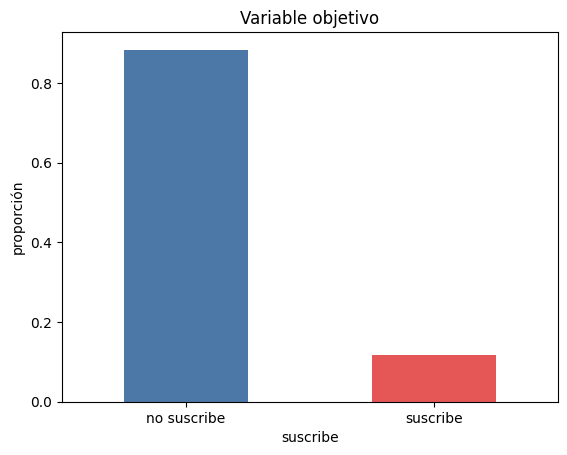

In [5]:
print(y.value_counts().rename({0: "no suscribe", 1: "suscribe"}))
y.value_counts(normalize=True).rename({0: "no suscribe", 1: "suscribe"}).plot.bar(color=["#4C78A8", "#E45756"])
plt.ylabel("proporción"); plt.title("Variable objetivo"); plt.xticks(rotation=0); plt.show()

## Hallazgo 1 · El resultado de la campaña previa

resultado_previo
success    64.7 %
other      16.7 %
failure    12.6 %
unknown     9.2 %
Name: suscribe, dtype: object


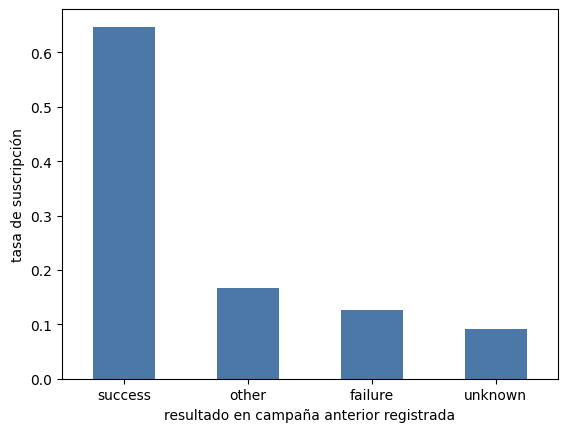

In [7]:
tasa_prev = df.groupby("resultado_previo")["suscribe"].mean().sort_values(ascending=False)
print((tasa_prev * 100).round(1).astype(str) + " %")
tasa_prev.plot.bar(color="#4C78A8")
plt.ylabel("tasa de suscripción"); plt.xlabel("resultado en campaña anterior registrada")
plt.xticks(rotation=0); plt.show()

## Hallazgo 2 · La situación financiera y deudas

In [9]:
for col, nombre in [("hipoteca", "Hipoteca"), ("prestamo", "Préstamo personal"), ("moroso", "Moroso")]:
    t = df.groupby(col)["suscribe"].mean()
    print(f"{nombre:<18} no: {t[0]:.1%}   sí: {t[1]:.1%}")

tramos_saldo = pd.cut(df["saldo"], [-10000, 0, 500, 2000, 150000], labels=["≤ 0", "1–500", "501–2000", "> 2000"])
print("\nSuscripción por saldo anual:")
print((df.groupby(tramos_saldo, observed=True)["suscribe"].mean() * 100).round(1).astype(str) + " %")

Hipoteca           no: 16.7%   sí: 7.7%
Préstamo personal  no: 12.7%   sí: 6.7%
Moroso             no: 11.8%   sí: 6.4%

Suscripción por saldo anual:
saldo
≤ 0          6.9 %
1–500       10.3 %
501–2000    13.0 %
> 2000      16.6 %
Name: suscribe, dtype: object


## Hallazgo 3 · La edad y los meses

In [11]:
tramos_edad = pd.cut(df["edad"], [0, 30, 45, 60, 100], labels=["≤ 30", "31–45", "46–60", "> 60"])
print("Suscripción por edad:")
print((df.groupby(tramos_edad, observed=True)["suscribe"].mean() * 100).round(1).astype(str) + " %")

print("\nTop 5 meses con mejor suscripcion:")
print((df.groupby("mes")["suscribe"].mean().sort_values(ascending=False).head(5) * 100).round(1).astype(str) + " %")

Suscripción por edad:
edad
≤ 30     16.3 %
31–45     9.9 %
46–60     9.8 %
> 60     42.3 %
Name: suscribe, dtype: object

Top 5 meses con mejor suscripcion:
mes
mar    52.0 %
dec    46.7 %
sep    46.5 %
oct    43.8 %
apr    19.7 %
Name: suscribe, dtype: object


## Hallazgos principales
1. **Clases desbalanceadas (11,7 % suscriben):** casi 9 de cada 10 clientes rechazan el depósito, por lo que no usaremos la accuracy.
2. **El historial previo es la señal más fuerte:** quienes suscribieron en una campaña anterior vuelven a suscribir en un **64,7 %**.
3. **La carga de deudas frena el ahorro:** tener hipoteca o préstamo personal reduce a la mitad la probabilidad de contratar el depósito; a mayor saldo anual, mayor conversión.
4. **Edad y estacionalidad importan:** mayores de 60 años (42,3 %) y jóvenes ≤ 30 años (16,3 %) convierten mucho más; meses como marzo, diciembre, septiembre y octubre superan el 43 % de éxito frente al 6,7 % de mayo.